In [74]:
#%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
#from ipynb.fs.full import utils  # optional, to import functions from *.ipynb files
from mintpy.utils import readfile, utils as ut, plot as pp
from mintpy.cli import view, tsview, plot_network, plot_transection
from mintpy.view import prep_slice, plot_slice
plt.rcParams.update({'font.size': 12})
from mintpy.objects import timeseries
import pandas as pd
import matplotlib.pyplot as plt
from mintpy.objects import ifgramStack
from mintpy.utils import network as pnet, ptime, readfile, utils0 as ut0

import shapefile as shp
from shapely.geometry import Point
from shapely.geometry import shape 
from sklearn.metrics import r2_score
import matplotlib
import glob
from osgeo import gdal, osr
from pyproj import Transformer, CRS
from pyproj.aoi import AreaOfInterest
from pyproj.database import query_utm_crs_info
import math
from scipy.stats import ranksums
from datetime import datetime
from matplotlib.ticker import MultipleLocator

In [75]:
shpfile = '/Users/boyazhang/Documents/Work/California/Shapefile/Sac/Project_sac.shp'
sf = shp.Reader(shpfile) 
sfRec = sf.records()
all_shapes = sf.shapes()
all_records = sf.records() 
feature = sf.shapeRecords()[0]
first = feature.shape.__geo_interface__
fs = 20
mapping = {0: 1, 2: 2, 4: 3, 7: 4, 8: 5, 9: 6}

In [76]:
shpsensor = '/Users/boyazhang/Documents/Work/California/Shapefile/Sac/water_depth_stations.shp'
sensorf = shp.Reader(shpsensor) 
senRec = sensorf.records()
sen_shapes = sensorf.shapes()
sen_records = sensorf.records() 

sensors = sensorf.shapeRecords()[0]
fields = [field[0] for field in sensorf.fields[1:]]  # Exclude the 'DeletionFlag' field

In [77]:
def calculate_rmse(actual_values, predicted_values):
    mse = np.mean((actual_values - predicted_values) ** 2)
    rmse = np.sqrt(mse)
    return rmse

def filterpixel(dtmind, sitename, latout, lonout):
    transformer = Transformer.from_crs("EPSG:4326", "EPSG:26910")
    dataset = gdal.Open("/Users/boyazhang/Documents/Work/California/Processing/DTM/" + dtmname[dtmind] + '_elev_m.tif')
    spatial_ref = dataset.GetProjection()
    geotransform = dataset.GetGeoTransform()
    raster_band = dataset.GetRasterBand(1)
    width = raster_band.XSize
    height = raster_band.YSize
    # Create a SpatialReference object
    srs = osr.SpatialReference(wkt=spatial_ref)

    # Get the EPSG code
    epsg_code = srs.GetAttrValue('AUTHORITY', 1)

    xout = np.zeros(latout.shape[0])
    yout = np.zeros(lonout.shape[0])
    for i in range(latout.shape[0]):
        xout[i], yout[i] = transformer.transform(latout[i], lonout[i])
    
    points = list(zip(xout, yout))
    
    elevs = np.zeros(latout.shape[0])
    ct = 0
    for point in points:
        x, y = point

        # Convert coordinates to pixel coordinates
        pixel_x = int((x - geotransform[0]) / geotransform[1])
        pixel_y = int((y - geotransform[3]) / geotransform[5])

        if (pixel_x >= 0 and pixel_y >=0 and pixel_x < width and pixel_y < height): ## control that the point is in the boundary
            elevs[ct] = raster_band.ReadAsArray(pixel_x, pixel_y, 1, 1)[0, 0]
        else:
            elevs[ct] = 10000 ## meaning it will be excluded
        ct = ct + 1
     
    sensor = sitename
    
    for i in range(len(sen_records)):
        sensname = sen_records[i][2] ## this is the unit name 
        if (sensor == sensname):
            sensor_elev = sen_records[i][-2] ## no use this stage. 
            lats = sen_records[i][-4]
            lons = sen_records[i][-5]
   
    sx, sy = transformer.transform(lats, lons)

    pixel_x = int((sx - geotransform[0]) / geotransform[1])
    pixel_y = int((sy - geotransform[3]) / geotransform[5])

    # Read value from raster band
    selev = raster_band.ReadAsArray(pixel_x, pixel_y, 1, 1)[0, 0]
#     selev = sensor_elev
#     if dtmind == 3: ## sact4c2 
#         selev = 30.28797
    print("elevation of sensor is:")
    print(selev)
    return np.where(elevs < selev) ## return the areas with elevation lower than the sensor. 

def plot_best():
    matplotlib.use('Agg') 
    fig, ax = plt.subplots()
    ID = range(end - start + 1)
    errmin = np.round(error[min_index], 2)
    errmin = errmin.item()

    plt.scatter(ID, wdv, label = 'Ground Reference', linestyle='-')
    plt.scatter(ID, poic[int(min_index[0])], label = 'InSAR Predictions', linestyle='-')

    plt.xlabel('SAR acquisition dates', fontsize = fs + 1)
    plt.ylabel('Reference vs. InSAR wd (cm)', fontsize = fs + 1)
    plt.xticks(fontsize=fs-0.5)
    plt.yticks(fontsize=fs-0.5)

    xltick = [dates[i] for i in ID]

    if len(ID) > 8:
        ID = ID[::4]
        xltick = xltick[::4]

    plt.xticks(ID, xltick)

    # Show the plot
    corr_coeff = np.corrcoef(wdv, poic[int(min_index[0]), :])[0, 1]
    r2 = corr_coeff * corr_coeff
    
    plt.text(4, -1,  r'RMSE=' + f'{errmin:.2f}' +'cm', fontsize=fs + 1, color='black')
    plt.savefig('./'  + folder + 'plot' + str(wu) + '.tif', bbox_inches='tight', dpi=300, format='tiff')

In [78]:
Path_stack = './inputs/'
stack_file = Path_stack + 'ifgramStack.h5'
temp = readfile.read(stack_file, datasetName='coherence', box=(0, 0, 1, 1))[0]
stack_obj = ifgramStack(Path_stack + 'ifgramStack.h5')
#### the 'self' variable in the utils1.py nonzero function is actually stack_obj defined above. 
stack_obj.open()
date12List = stack_obj.get_date12_list(dropIfgram=False) ## This is the reference and secondary intferograms dates
dateList = stack_obj.get_date_list(dropIfgram=False) ## This is the acquisiton dates

date12List = ptime.yyyymmdd_date12(date12List)
dates, datevector = ptime.date_list2vector(dateList) ## datetime.datetime format - good!
date = readfile.read(stack_file, datasetName='date') ### with 'b' and lots of unnecessary items

open ifgramStack file: ifgramStack.h5


In [79]:
file_names = os.listdir("/Users/boyazhang/Documents/Work/California/Processing/DTM/")

# Filter the list to include only files with '.tif' extension and start with 'Sac'
sacs = [file for file in file_names if file.startswith('Sac') and file.endswith('.tif')]
dtmname = []

# Iterate through the desired files
for file in sacs:
    # Get the substring before the first '_'
    substring = file.split('_')[0]
    dtmname.append(substring)

In [80]:
ifgram_stack = './inputs/ifgramStack.h5'
geom_file = './inputs/geometryGeo.h5' 
mode = 2 ### mode 1 single, mode 2 multi
if mode == 2:
    folder = 'Results/Single/'
elif mode == 2:
    folder = 'Results/Multi/'
else:
    folder = 'Results/TestSingle/'

temp = readfile.read(ifgram_stack, datasetName='coherence', box=(0, 0, 1, 1))[0]
stack_obj = ifgramStack(ifgram_stack)                    
coh = stack_obj.read(datasetName='coherence') ## connections, y, x
xrg = coh.shape[2]
yrg = coh.shape[1]
k   = coh.shape[0]
meta = readfile.read_attribute(ifgram_stack)
coord_obj = ut.coordinate(meta, geom_file)
lat_stack_all = np.zeros((xrg, yrg))
lon_stack_all = np.zeros((xrg, yrg))
lat_1d = np.zeros((xrg * yrg))
lon_1d = np.zeros((xrg * yrg))
inclusion = np.zeros(xrg * yrg)

ct = 0
for i in range(xrg):
    for j in range(yrg):
        lat, lon = coord_obj.radar2geo(j, i)[0:2]
        lat_stack_all[i, j] = lat
        lon_stack_all[i, j] = lon
        lat_1d[ct] = lat
        lon_1d[ct] = lon
        ct = ct + 1

reading coherence data from file: ./inputs/ifgramStack.h5 ...


In [67]:
######### Mintpy Command - try other options with modify_network ##############################
for wu in range(0, 11, 1):
    print("Wetland Unit is: {x}".format(x = wu))
#     if wu == 5 or wu == 1 or wu == 3 or wu == 6:
#         continue
    
    if wu != 9: ## no RP found. 
        continue
#     if  wu!=0 and wu!=2 and wu!=4 and wu!=7 and wu!=8 and wu!=9: ## no RP found. 
#         continue
        
    if wu == 6:
        ref = -1
    else:
        ref = 0
    
        
    wucmd = str(wu)
    
    if mode == 1:
        cmd1 = "smallbaselineApp.py ./Config/Single/try_"
    elif mode == 2:
        cmd1 = "smallbaselineApp.py ./Config/Multi/try_"
    else:
        cmd1 = "smallbaselineApp.py ./Config/TestSingle/try_"
    cmd2 = ".cfg --dostep "
    step1 = "modify_network"
    step2 = "rm maskConnComp.h5"
    step3 = "generate_mask.py  inputs/ifgramStack.h5 --nonzero -o maskConnComp.h5 --update"
    step4 = "reference_point"
    step5 = "invert_network"
    step6 = "timeseries2velocity.py timeseries.h5"
    command = cmd1 + wucmd + cmd2 + step1
    !{command}
    !rm maskConnComp.h5
    !generate_mask.py  inputs/ifgramStack.h5 --nonzero -o maskConnComp.h5 --update
    command = cmd1 + wucmd + cmd2 + step4 
    !{command}
    command = cmd1 + wucmd + cmd2 + step5 
    !{command}
    command = step6
    !{command}
    #     !smallbaselineApp.py try_4.cfg --dostep modify_network
    #     !rm maskConnComp.h5
    #     !generate_mask.py  inputs/ifgramStack.h5 --nonzero -o maskConnComp.h5 --update
    #     !smallbaselineApp.py try_4.cfg --dostep reference_point
    #     !smallbaselineApp.py try_4.cfg --dostep invert_network
    site = wu
    if site == 0:
        #start = 3
        start = 4
        end = 6
        sitename = 'SacT34c1'
        FID = 0
        wd = pd.read_csv('./wd/wdts_t34c1.csv')
        #dates = ['20170307', '20170319', '20170331', '20170412', '20170424', '20170506', '20170518', '20170530', '20170611', '20170623', '20170705', '20170717','20170729', '20170810','20170822', '20170903']
        #dates = ['20170307', '20170319', '20170331', '20170412']
        dates = ['20170319', '20170331', '20170412']
    elif site == 10:
        start = 4
        end = 19
        sitename = 'SacT34c1'
        FID = 0
        wd = pd.read_csv('./wd/wdts_t34c1.csv')
        #dates = ['20170307', '20170319', '20170331', '20170412', '20170424', '20170506', '20170518', '20170530', '20170611', '20170623', '20170705', '20170717','20170729', '20170810','20170822', '20170903']
        #dates = ['20170307', '20170319', '20170331', '20170412']
        dates = ['20170319', '20170331', '20170412','20170424', '20170506', '20170518', '20170530', '20170611', '20170623', '20170705', '20170717','20170729', '20170810','20170822', '20170903', '20170915']
    elif site == 3: # T4c1
        start = 15
        end = 20 ## actually it is 20
        sitename = 'SacT4c1'
        FID = 3
        wd = pd.read_csv('./wd/wdts_t4c1.csv')
        dates = ['20170729', '20170810','20170822', '20170903', '20170915', '20170927']
    elif site == 31: # T4c2
        start = 21
        end = 33 ## actually it is 20
        #end = 30
        sitename = 'SacT4c1_winter'
        FID = 3 
        wd = pd.read_csv('./wd/wdts_t4c1.csv')
        dates = ['20171009', '20171021', '20171102', '20171114', '20171126', '20171208', '20171220', '20180101','20180113', '20180125', '20180206', '20180218', '20180302']
        #dates = ['20171009', '20171021', '20171102', '20171114', '20171126', '20171208', '20171220', '20180101','20180113', '20180125']
    elif site == 2: # T4c2
        start = 6
        end = 20 ## actually it is 20
        sitename = 'SacT4c2'
        FID = 2 
        wd = pd.read_csv('./wd/wdts_t4c2.csv')
        dates = ['20170412', '20170424', '20170506', '20170518', '20170530', '20170611', '20170623', '20170705', '20170717','20170729', '20170810','20170822', '20170903', '20170915', '20170927']
    elif site == 4: ## SacP1Ac1
        start = 9
        end = 18
        sitename = 'SacP1Ac1'
        FID = 4 
        wd = pd.read_csv('./wd/wdts_p1ac1.csv')
        dates = ['20170518', '20170530', '20170611', '20170623', '20170705', '20170717','20170729', '20170810','20170822', '20170903']
    elif site == 6:
        start = 8
        end = 16
        sitename = 'SacT9c2'
        FID = 6
        wd = pd.read_csv('./wd/wdts_t9c2.csv')  
        dates = ['20170506','20170518', '20170530', '20170611', '20170623', '20170705', '20170717','20170729', '20170810']
    elif site == 8:
        start = 15
        #start = 16
        end = 19
        FID = 8
        sitename = 'SacT41c1'
        wd = pd.read_csv('./wd/wdts_t41c1.csv')
        dates = ['20170729', '20170810','20170822', '20170903', '20170915']
        #dates = ['20170810','20170822', '20170903', '20170915']
    elif site == 81:
        start = 22
        end = 36
        FID = 8
        sitename = 'SacT41c1_winter'
        wd = pd.read_csv('./wd/wdts_t41c1.csv')
        dates = ['20171021', '20171102','20171114', '20171126', '20171208', '20171220', '20180101', '20180113', '20180125','20180206','20180218','20180302','20180314','20180326','20180407']
    elif site == 1:
        start = 13
        end = 19
        FID = 1
        sitename = 'SacT29c2'
        wd = pd.read_csv('./wd/wdts_t29c2.csv')
        dates = ['20170705', '20170717', '20170729', '20170810','20170822', '20170903', '20170915']
    elif site == 7:
        start = 8
        end = 18
        FID = 7
        sitename = 'SacP11c2'
        wd = pd.read_csv('./wd/wdts_p11c2.csv')
        dates = ['20170506','20170518', '20170530', '20170611', '20170623', '20170705', '20170717', '20170729', '20170810','20170822', '20170903']
    elif site == 9:
        start = 8
        end = 21
        FID = 9
        sitename = 'SacT4c3'
        wd = pd.read_csv('./wd/wdts_t4c3.csv')
        dates = ['20170506','20170518', '20170530', '20170611', '20170623', '20170705', '20170717', '20170729', '20170810','20170822', '20170903','20170915', '20170927','20171009']
    period = range(start, end + 1)

    ct = 0
    
    inclusion = np.zeros(xrg * yrg)
    for i in range(xrg):
        for j in range(yrg): 
            point_to_check = (lon_stack_all[i, j], lat_stack_all[i, j])
            #for tt = 3
            boundary = all_shapes[FID] # get a boundary polygon
            if Point(point_to_check).within(shape(boundary)): # make a point and see if it's in the polygon
                inclusion[ct] = 1
            ct = ct + 1
    
    ################### Results #####################################
    ################# Find out the best WETLAND PIXEL match with the wd measurements ! ######################

    wdv = wd.iloc[:, 2].values
    wdv = wdv[period]
    wdv = wdv - wdv[ref]

    tsobj = timeseries('timeseries.h5')


    data = tsobj.read(datasetName=dates)
    wetpix = np.where(inclusion == 1)[0]
    wetpixn = len(np.where(inclusion == 1)[0])

    inc_angle = readfile.read('inputs/geometryGeo.h5', datasetName='incidenceAngle')[0]
    poic = np.zeros((wetpixn, end - start + 1)) ## for each wetland pixel, a timeseries 
    error = np.zeros(wetpixn) ## calculate the rmse for each wetland pixel
    tcall = np.zeros(wetpixn)
    pvall = np.zeros(wetpixn)
                  
    coh = stack_obj.read(datasetName='coherence') ## connections, y, x
    
    insar_tc_path = 'temporalCoherence.h5'
    dsName = 'temporalCoherence'
    tc = readfile.read(insar_tc_path, datasetName=dsName, print_msg=False)[0]
    pv = readfile.read('velocity.h5', datasetName='velocity', print_msg=False)[0]
   
    for i in range(wetpixn):
        yi = wetpix[i] % yrg
        xi = int((wetpix[i]  - yi) / yrg)
        angle = inc_angle[yi, xi]
        angle = angle / 180 * np.pi 
        poi = data[:, yi, xi]
        poic[i, :] = poi / np.cos(angle)
        poic[i, :] = poic[i, :] * 100
        poic[i, :] = poic[i, :] - poic[i, ref]
        error[i] = calculate_rmse(wdv, poic[i, :])
        if (wu == 10):
            error[i] = calculate_rmse(wdv[:2], poic[i, :2])
        tcall[i] = tc[yi, xi]
        pvall[i] = pv[yi, xi]
        
    min_index = np.where(error == np.min(error))
    plot_best()
    #print('the min index is {f}'.format(f = min_index))
    #     yo = int(wetpix[min_index] % yrg)
    #     xo = int((wetpix[min_index]  - yo) / yrg)

    print('the least rmse is')
    print(error[min_index])
    
    
    ###### DTM FILTER ####################################
    latout = np.zeros(wetpixn)
    lonout = np.zeros(wetpixn)
    IDout = range(wetpixn)

    for i in range(wetpixn): ## output the lat, lon, and rmse for each wetland pixel!
        lati = lat_1d[wetpix[i]]
        latout[i] = np.round(lati, 4)
        loni = lon_1d[wetpix[i]]
        lonout[i] = np.round(loni, 4)
    
    for i in range(len(dtmname)):
        if (sitename == dtmname[i]): ## find the matched DTM product
            dtmfilter = filterpixel(i, sitename, latout, lonout)
    dtmfilter = np.array(dtmfilter, dtype=np.int64)
    dfilt = dtmfilter.flatten()
    
    fifty = np.zeros(poic.shape[1])
    
    #pred = poic[int(min_index[0])] ## instead of using the best value, using the median value
#     for i in range(poic.shape[1]):
#         fifty[i] = np.percentile(poic[dfilt, i], 50) ## for each time the median value in space filtered by DEM

    fifty = poic[int(min_index[0])] 
    true = wdv
    ind = np.arange(0, len(fifty), 1)  
    dates_num = [int(num) for num in dates]
    out = np.vstack((ind, dates_num, fifty, true))
    out = out.transpose()
    with open('./'  + folder + 'site ' + str(wu) + '.csv',"w") as f:
            np.savetxt(f, out, delimiter=",", header="ID, dates, pred, true", fmt="%f")
  
    
    ################ Output and Save ######################
    
        
    IDout = np.array(IDout)
    IDf = IDout[dfilt]    
    latf = latout[dfilt]    
    lonf = lonout[dfilt]  
    errf = error[dfilt]
    wetpixf = wetpix[dfilt]
    tcf = tcall[dfilt]
    pvf = pvall[dfilt]
    
    meanerr = np.mean(errf)
    stderr = np.std(errf)
    print("mean value is {x}".format(x = meanerr))
    #print("std value is {x}".format(x = stderr))
    
    with open('./'  + folder + 'hist_' + wucmd + '.csv',"w") as f:
        np.savetxt(f, np.array([[wu, meanerr, stderr]]), delimiter=",", 
               fmt="%f")
    
    out = np.vstack((IDf, latf, lonf, errf, tcf, pvf, wetpixf))
    out = out.transpose()
    del inclusion
    
#     with open('./'  + folder + 'rmse_' + wucmd + '.csv',"w") as f:
#         np.savetxt(f, out, delimiter=",", header="id, lat,lon,rmse, index", 
#                fmt="%f")
    with open('./'  + folder + 'rmse_' + wucmd + '.csv',"w") as f:
        np.savetxt(f, out, delimiter=",", header="id, lat,lon,rmse, tc, pv, index", 
               fmt="%f")
        
    if mode == 1:
        poicmulti = poic 

Wetland Unit is: 0
Wetland Unit is: 1
Wetland Unit is: 2
Wetland Unit is: 3
Wetland Unit is: 4
Wetland Unit is: 5
Wetland Unit is: 6
Wetland Unit is: 7
Wetland Unit is: 8
Wetland Unit is: 9
MintPy version 1.5.2.post1, date 2023-08-10
--RUN-at-2024-04-04 11:13:07.463450--
Current directory: /Users/boyazhang/Documents/Work/California/Processing/SacFull
Run routine processing with smallbaselineApp.py on steps: ['modify_network']
Remaining steps: ['reference_point', 'quick_overview', 'correct_unwrap_error', 'invert_network', 'correct_LOD', 'correct_SET', 'correct_troposphere', 'deramp', 'correct_topography', 'residual_RMS', 'reference_date', 'velocity', 'geocode', 'google_earth', 'hdfeos5']
--------------------------------------------------
Project name: try_9
Go to work directory: /Users/boyazhang/Documents/Work/California/Processing/SacFull
read custom template file: /Users/boyazhang/Documents/Work/California/Processing/SacFull/Config/Multi/try_9.cfg
update default template based on inpu

read temporal/spatial baseline info from file: /Users/boyazhang/Documents/Work/California/Processing/SacFull/inputs/ifgramStack.h5
open ifgramStack file: ifgramStack.h5
calculating spatial mean of coherence in file /Users/boyazhang/Documents/Work/California/Processing/SacFull/inputs/ifgramStack.h5 ...
[==================================================] 1023/1023    2s /     0s
write average value in space into text file: coherenceSpatialAvg.txt
number of acquisitions: 174
number of interferograms: 1023
shift all perp baseline by 47.346778869628906 to zero mean for plotting
--------------------------------------------------
number of interferograms marked as drop: 998
number of interferograms marked as keep: 25
number of acquisitions marked as drop: 160
['20161225', '20170118', '20170223', '20170307', '20170319', '20170331', '20170412', '20170424', '20171021', '20171102', '20171114', '20171126', '20171208', '20171220', '20180101', '20180113', '20180125', '20180206', '20180218', '201803

Input data seems to be geocoded. Lookup file not needed.

ifgram_inversion.py /Users/boyazhang/Documents/Work/California/Processing/SacFull/inputs/ifgramStack.h5 -t /Users/boyazhang/Documents/Work/California/Processing/SacFull/smallbaselineApp.cfg --update
read input option from template file: /Users/boyazhang/Documents/Work/California/Processing/SacFull/smallbaselineApp.cfg
translate numWorker = 70% to 8
use dataset "unwrapPhase" by default
--------------------------------------------------
update mode: ON
1) output files already exist: ['timeseries.h5', 'temporalCoherence.h5', 'numInvIfgram.h5'].
2) output dataset is newer than input dataset: unwrapPhase.
3) NOT all the metadata are the same: ['REF_Y', 'REF_X']
run or skip: run.
save the original settings of ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS']
set OMP_NUM_THREADS = 1
set OPENBLAS_NUM_THREADS = 1
set MKL_NUM_THREADS = 1
set NUMEXPR_NUM_THREADS = 1
set VECLIB_M

[==================================================] 10276/10276 pixels    1s /     0s
converting LOS phase unit from radian to meter
[======================= 83% =============>        ] 10000/12111 pixels    1s /     0s
FUTURE #1 complete. Time used: 2 seconds
[==================================================] 12111/12111 pixels    1s /     0s
converting LOS phase unit from radian to meter
[==================================================] 12111/12111 pixels    1s /     0s
converting LOS phase unit from radian to meter
[======================= 96% ===================>  ] 11600/12110 pixels    1s /     0s
FUTURE #2 complete. Time used: 3 seconds

FUTURE #3 complete. Time used: 3 seconds
[==================================================] 12111/12111 pixels    1s /     0s
converting LOS phase unit from radian to meter
[==================================================] 12111/12111 pixels 
converting LOS phase unit from radian to meter

FUTURE #4 complete. Time used: 3 seconds
[===

/var/folders/xc/0nh5gdkn5sz1hyvvnl87lbc00000gn/T/ipykernel_7521/652474788.py:73: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.scatter(ID, poic[int(min_index[0])], label = 'InSAR Predictions', linestyle='-')
/var/folders/xc/0nh5gdkn5sz1hyvvnl87lbc00000gn/T/ipykernel_7521/652474788.py:89: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  corr_coeff = np.corrcoef(wdv, poic[int(min_index[0]), :])[0, 1]
/var/folders/xc/0nh5gdkn5sz1hyvvnl87lbc00000gn/T/ipykernel_7521/3930068376.py:231: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your arra

In [31]:
mode

2

In [13]:
######### Get coherence for Unit 6 for time of interest #####
conn = 6
trgoi = range(8, 22) ## SacT4c3
ndi = range(trgoi[0] * conn, trgoi[-1] * conn + 1) ## the index for interferograms
ndi = [x for x in ndi if x % conn == 0]
cohfilt = coh[ndi, :, :]

In [14]:
cohfilt.shape

(14, 367, 259)

In [15]:
type(cohfilt)

numpy.ndarray

In [31]:
coh2d = np.zeros((14, wetpixn))
for i in range(wetpixn):
    yi = wetpix[i] % yrg
    xi = int((wetpix[i]  - yi) / yrg)
    coh2d[:, i] = cohfilt[:, yi, xi]
coh2d = coh2d[:, dfilt]

In [34]:
out = np.vstack((IDf, latf, lonf, coh2d))
out = out.transpose()

with open('./'  + folder + 'coh2d' + wucmd + '.csv',"w") as f:
    np.savetxt(f, out, delimiter=",", header="id, lat,lon,ts", 
           fmt="%f")

In [52]:
%clear
matplotlib.use('Agg')



plt.plot(ID, wdv, color='black', markersize = 3, label = 'Ground reference')

plt.plot(ID, resrec, color='#fc8d59', markersize = 3, label = 'InSAR prediction')
plt.xlabel('2017', fontsize = fs)
plt.ylabel('InSAR and Ref wd (cm)', fontsize = fs)
xltick = nID
plt.xticks(xltick, xtl)
plt.tick_params(axis='x', labelsize=18)  # Adjust fontsize as needed for the x-axis tick labels
plt.tick_params(axis='y', labelsize=18)  #
plt.legend(loc='center right', fontsize = 18)
#plt.plot(ID, sing, color='#998ec3', markersize = 3)
plt.show()
plt.savefig('waterpixel.tif', bbox_inches='tight', dpi=300, format='tiff')

/var/folders/xc/0nh5gdkn5sz1hyvvnl87lbc00000gn/T/ipykernel_5108/1471239616.py:17: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [41]:
######## Combine csv rmse ################################

resPath = '/Users/boyazhang/Documents/Work/California/Processing/SacFull/Results/Single/'
all_files = glob.glob(resPath + 'rmse*.csv')

# Exclude the file 'rmse_10.csv'
include_files = ['rmse_0.csv', 'rmse_2.csv', 'rmse_4.csv', 'rmse_7.csv', 'rmse_8.csv', 'rmse_9.csv']

res = pd.DataFrame()

for i in range(len(include_files)):
    temp = pd.read_csv(resPath + include_files[i], header=None, skiprows=1)
    #temp = temp[1:, :]
    value = temp.iloc[:, 3]
    print(np.median(value))
    res = pd.concat([res, temp], axis=0, ignore_index=True)
    

res.to_csv('rmse_all_s.csv', index=False)     
#df_sorted = res.sort_values(by=res.columns[0], ascending=True)
#df = df_sorted.iloc[9:]
# df = df.apply(pd.to_numeric, errors='coerce')
#df[[0, 4]] = df[[0, 4]].astype(float)
# with open('./'  + 'rmse_all_m' + '.csv',"w") as f:
#     np.savetxt(f, df, delimiter=",", fmt="%f")

0.405567
0.57258
1.65371
1.525843
2.454504
2.234735


In [68]:
############ Get the dates based on the string ####################
wu = site
sdate = dates[0]
edate = dates[-1]
sobject = datetime.strptime(sdate, '%Y%m%d')
eobject = datetime.strptime(edate, '%Y%m%d')
date_difference = eobject - sobject

# Access the days attribute
span = date_difference.days
span

fdate = sobject.replace(day=1)

date_difference = sobject - fdate
sd = date_difference.days
span = span + sd

### dates from April to September
monday = [30, 31, 30, 31, 31, 30]
xnewt = np.zeros(6)

oID = range(end - start + 1)

## Create a new set of ID #######

if wu == 2:
    monthsf = [4, 5, 6, 7, 8, 9,10]
    monthss = [5, 6, 7, 8, 9, 10]
    xtl = ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct']
elif wu == 4:
    monthsf = [5, 6, 7, 8, 9]
    monthss = [6, 7, 8, 9]
    xtl = ['May', 'Jun', 'Jul', 'Aug', 'Sep']
elif wu == 0:
    monthsf = [3, 4]
    monthss = [4]
    xtl = ['March', 'April']
elif wu == 7:
    monthsf = [5, 6, 7, 8, 9]
    monthss = [6, 7, 8, 9]
    xtl = ['May', 'Jun', 'Jul', 'Aug','Sep']
elif wu == 8:
    monthsf = [7, 8, 9]
    monthss = [8, 9]
    xtl = ['Jul', 'Aug','Sep']
elif wu == 9:
    monthsf = [5, 6, 7, 8, 9, 10]
    monthss = [6, 7, 8, 9, 10]
    xtl = ['May', 'Jun', 'Jul', 'Aug','Sep','Oct']
elif wu == 10:
    monthsf = [3, 4, 5, 6, 7, 8, 9]
    monthss = [4, 5, 6, 7, 8, 9]
    xtl = ['Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug','Sep']
    
nID = np.zeros(len(monthsf))
# Generate a list of datetime objects for the first day of each month
fdom = [datetime(year=2017, month=month, day=1) for month in monthss]

for i in range(len(monthss)):
    date_difference = fdom[i] - fdate
    dif = date_difference.days
    nID[i + 1] = dif


    
### Generate the index corresponding to SAR date ####

sarind = np.zeros(len(dates))

for i in range(len(dates)):
    temp = datetime.strptime(dates[i], '%Y%m%d')
    date_difference = temp - fdate
    dif = date_difference.days
    sarind[i] = dif

sarind = sarind.astype(int)

In [69]:
if 66 in dfilt:
    print("Number is in the array")
else:
    print("Number is not in the array")

Number is in the array


In [70]:
################ Record the poic from multi ######

ID = sarind
eightym = np.zeros(poicmulti.shape[1])
twentym = np.zeros(poicmulti.shape[1])

for i in range(poic.shape[1]):
    eightym[i] = np.percentile(poicmulti[:, i], 90)
    twentym[i] = np.percentile(poicmulti[:, i], 10)
    
# Fit curves to the data points
coeffs_min = np.polyfit(ID, twentym, 7)  # Fit a polynomial of degree 3
coeffs_max = np.polyfit(ID, eightym, 7)


In [72]:
###################### Plot #######################
matplotlib.use('Agg')

#matplotlib.use('TkAgg') 
#%matplotlib inline
fig, ax = plt.subplots()
#min_index = np.where(wetpix == 12538)[0]
#min_index = mini
plt.rcParams['font.family'] = 'Arial'

if isinstance(min_index, tuple):
    min_index = min_index[0][0]

ID = sarind



#colors = ['#d53e4f','#f46d43','#fdae61','#fee08b','#e6f598','#abdda4','#66c2a5','#3288bd']
#labels = ['Px 1', 'Px 2', 'Px 3', 'Px 4', 'Px 5', 'Px 6', 'Px 7']

# Plot circles for each color with the corresponding labels
eighty = np.zeros(poic.shape[1])
twenty = np.zeros(poic.shape[1])
fifty = np.zeros(poic.shape[1])
for i in range(poic.shape[1]):
    eighty[i] = np.percentile(poic[:, i], 90)
    twenty[i] = np.percentile(poic[:, i], 10)
    fifty[i] = np.percentile(poic[:, i], 50)
# Fit curves to the data points
coeffs_min = np.polyfit(ID, twenty, 7)  # Fit a polynomial of degree 3
coeffs_max = np.polyfit(ID, eighty, 7)

# Generate x values for plotting the curves
x_values = np.linspace(ID.min(), ID.max(), 100)

# Calculate y values for the fitted curves
y_values_min = np.polyval(coeffs_min, x_values)
y_values_max = np.polyval(coeffs_max, x_values)

# Plot the fitted curves
plt.plot(ID, twenty, color='#fc8d59', label='90 and 10 percentile for auto')
plt.plot(ID, eighty, color='#fc8d59')
plt.plot(ID, eightym, color='#998ec3', label='90 and 10 percentile for manual')
plt.plot(ID, twentym, color='#998ec3')


# Shade the area between the curves
plt.fill_between(ID, twenty, eighty, color='#fc8d59')
plt.fill_between(ID, twentym, eightym, color='#998ec3', alpha=0.5)
plt.scatter(ID, wdv, label = 'Ground reference', s = 50, color = 'black')

plt.scatter(ID, poic[min_index], label = 'The best InSAR predictions', s = 50, color = '#91cf60') 
plt.plot(ID, fifty, color='#ffffbf', label = 'InSAR median predictions', linewidth = 3)
# for i in range(len(dfilt)):
    
#     if dfilt[i] != min_index:
#         plt.scatter(ID, poic[dfilt[i]], s  = 30)
#     else:
#         plt.scatter(ID, poic[dfilt[i]], s  = 70, marker='*')

plt.xlabel('2017', fontsize = fs)
plt.ylabel('Reference vs InSAR wd (cm)', fontsize = fs)
plt.xticks(fontsize=fs-3)
plt.yticks(fontsize=fs)
 
#xltick = [dates[i] for i in ID]

xltick = nID

# if len(ID) > 8:
#     ID = ID[::4]
#     xltick = xltick[::4]

plt.xticks(xltick, xtl)
plt.ylim(-6, 2)

# Set y-axis tick labels
plt.yticks([-6, -4, -2, 0, 2], ['-6', '-4', '-2', '0', '2'])

major_locator = MultipleLocator(1)
minor_locator = MultipleLocator(0.5)

# Set major and minor y-axis ticks
ax.yaxis.set_major_locator(major_locator)
ax.yaxis.set_minor_locator(minor_locator)

corr_coeff = np.corrcoef(wdv, poic[min_index, :])[0, 1]
r2 = corr_coeff * corr_coeff


plt.legend(loc='center left', bbox_to_anchor=(-0.5, -0.5))
if wu == 2:
    plt.text(60, -.5,  r'The Best RMSE=' + f'{error[min_index]:.2f}' +'cm', fontsize=fs, color='black')
    plt.show()
    plt.savefig('plot' + str(2) + str(mode) + '.tif', bbox_inches='tight', dpi=300, format='tiff')
    np.savez('site2.npz', v1=twenty, v2=eighty, v3=twentym, v4 = eightym, v5=wdv, v6=ID, v7=poic[min_index],v8=fifty)
elif wu == 4:
    plt.text(40, 1.2,  r'The Best RMSE=' + f'{error[min_index]:.2f}' +'cm', fontsize=fs, color='black')
    plt.show()
    plt.savefig('plot' + str(4) + str(mode) + '.tif', bbox_inches='tight', dpi=300, format='tiff')
    np.savez('site4.npz', v1=twenty, v2=eighty, v3=twentym, v4 = eightym, v5=wdv, v6=ID, v7=poic[min_index],v8=fifty)
elif wu == 0:
    plt.text(ID[0] , -4,  r'The Best RMSE=' + f'{error[min_index]:.2f}' +'cm', fontsize=fs, color='black')
    plt.xlim(ID[0] - 2, ID[-1] + 2)
    plt.show()
    plt.savefig('plot' + str(0) + str(mode) + '.tif', bbox_inches='tight', dpi=300, format='tiff')
    np.savez('site0.npz', v1=twenty, v2=eighty, v3=twentym, v4 = eightym, v5=wdv, v6=ID, v7=poic[min_index],v8=fifty)
elif wu == 7:
    plt.text(40, 1.1,  r'The Best RMSE=' + f'{error[min_index]:.2f}' +'cm', fontsize=fs, color='black')
    plt.xlim(ID[0] - 2, ID[-1] + 2)
    plt.show()
    plt.savefig('plot' + str(7) + str(mode) + '.tif', bbox_inches='tight', dpi=300, format='tiff')
    np.savez('site7.npz', v1=twenty, v2=eighty, v3=twentym, v4 = eightym, v5=wdv, v6=ID, v7=poic[min_index],v8=fifty)
elif wu == 8:
    plt.text(40, 3,  r'The Best RMSE=' + f'{error[min_index]:.2f}' +'cm', fontsize=fs, color='black')
    plt.ylim(-6, 5)
    # Set y-axis tick labels
    plt.yticks([-6, -4, -2, 0, 2, 4], ['-6', '-4', '-2', '0', '2', '4'])
    plt.xlim(ID[0] - 2, ID[-1] + 2)
    plt.show()
    plt.savefig('plot' + str(8) + str(mode) + '.tif', bbox_inches='tight', dpi=300, format='tiff')
    np.savez('site8.npz', v1=twenty, v2=eighty, v3=twentym, v4 = eightym, v5=wdv, v6=ID, v7=poic[min_index],v8=fifty)
elif wu == 9:
    plt.text(10, -4,  r'The Best RMSE=' + f'{error[min_index]:.2f}' +'cm', fontsize=fs, color='black')
    plt.xlim(ID[0] - 2, ID[-1] + 2)
    plt.show()
    plt.savefig('plot' + str(9) + str(mode) + '.tif', bbox_inches='tight', dpi=300, format='tiff')
    np.savez('site9.npz', v1=twenty, v2=eighty, v3=twentym, v4 = eightym, v5=wdv, v6=ID, v7=poic[min_index],v8=fifty)

/var/folders/xc/0nh5gdkn5sz1hyvvnl87lbc00000gn/T/ipykernel_7521/1780657752.py:126: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [ ]:
###################### Plot for Unit 1 Extension #######################
matplotlib.use('Agg')

#matplotlib.use('TkAgg') 
#%matplotlib inline
fig, ax = plt.subplots()
#min_index = np.where(wetpix == 12538)[0]
#min_index = mini
plt.rcParams['font.family'] = 'Arial'

if isinstance(min_index, tuple):
    min_index = min_index[0][0]

ID = sarind

#colors = ['#d53e4f','#f46d43','#fdae61','#fee08b','#e6f598','#abdda4','#66c2a5','#3288bd']
#labels = ['Px 1', 'Px 2', 'Px 3', 'Px 4', 'Px 5', 'Px 6', 'Px 7']

# Plot circles for each color with the corresponding labels
eighty = np.zeros(poic.shape[1])
twenty = np.zeros(poic.shape[1])
fifty = np.zeros(poic.shape[1])

for i in range(poic.shape[1]):
    eighty[i] = np.percentile(poic[:, i], 90)
    twenty[i] = np.percentile(poic[:, i], 10)
    fifty[i] = np.percentile(poic[:, i], 50)

x_values = np.linspace(ID.min(), ID.max(), 100)


# Plot the fitted curves
plt.plot(ID, twenty, color='#fc8d59', label='90 and 10 percentile for auto')
plt.plot(ID, eighty, color='#fc8d59')

# Shade the area between the curves
plt.fill_between(ID, twenty, eighty, color='#fc8d59')
plt.scatter(ID[0:3], wdv[0:3], label = 'Ground reference', s = 50, color = 'black')
plt.scatter(ID[3:-1], wdv[3:-1], label = 'Reference (Not Valid)', s = 50, color = 'black', marker='*')
plt.scatter(ID[-1], wdv[-1], s = 50, color = 'black')

plt.scatter(ID, poic[min_index], label = 'The best InSAR predictions', s = 50, color = '#91cf60') 
plt.plot(ID, fifty, color='#ffffbf', label = 'InSAR median predictions', linewidth = 3)

plt.xlabel('2017', fontsize = fs)
plt.ylabel('Reference vs. InSAR wd (cm)', fontsize = fs)
plt.xticks(fontsize=fs-3)
plt.yticks(fontsize=fs)
 
#xltick = [dates[i] for i in ID]

xltick = nID


plt.xticks(xltick, xtl)

major_locator = MultipleLocator(1)
minor_locator = MultipleLocator(0.5)

# Set major and minor y-axis ticks
ax.yaxis.set_major_locator(major_locator)
ax.yaxis.set_minor_locator(minor_locator)

corr_coeff = np.corrcoef(wdv, poic[min_index, :])[0, 1]
r2 = corr_coeff * corr_coeff
plt.legend(loc='center left', bbox_to_anchor=(-0.5, -0.5))

if wu == 10:
    plt.text(65, 0.5,  r'The Best RMSE=' + f'{error[min_index]:.2f}' +'cm', fontsize=fs, color='black')
    plt.xlim(ID[0] - 2, ID[-1] + 2)
    plt.show()
    plt.savefig('plot' + str(10) + str(mode) + '.tif', bbox_inches='tight', dpi=300, format='tiff')

In [ ]:
wdv

NameError: name 'min_index' is not defined

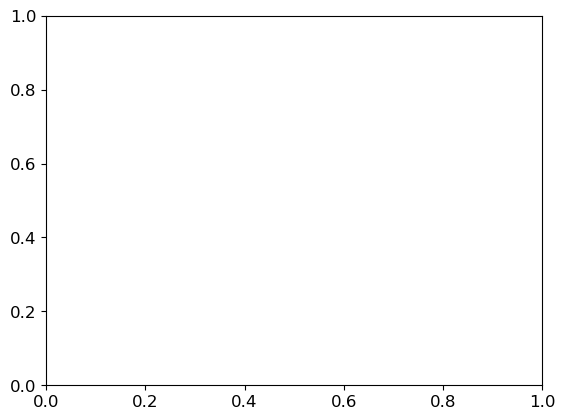

In [8]:
###################### Plot #######################
#matplotlib.use('Agg')
#matplotlib.use('TkAgg') 
%matplotlib inline
fig, ax = plt.subplots()
#min_index = np.where(wetpix == 12538)[0]
#min_index = mini
plt.rcParams['font.family'] = 'Arial'

if isinstance(min_index, tuple):
    min_index = min_index[0][0]

#ID = range(end - start + 1)
ID = sarind
#min_index = 11 ## plot the first wetland pixel
errmin = np.round(error[min_index], 2)
yo = int(wetpix[min_index] % yrg)
xo = int((wetpix[min_index]  - yo) / yrg)
errmin = errmin.item()
lati = lat_stack_all[xo, yo]
lati = np.round(lati, 4)
loni = lon_stack_all[xo, yo]
loni = np.round(loni, 4)

plt.scatter(ID, wdv, label = 'Ground reference')
#plt.scatter(ID, poic[int(min_index[0])], label = 'InSAR Predictions', linestyle='-')
plt.scatter(ID, poic[min_index], label = 'InSAR predictions', s  = 50)

#ax.plot(ID, wdv, color='red', linestyle='-')
#ax.plot(ID, poic[int(min_index[0])], color='red', linestyle='-')

plt.xlabel('2017', fontsize = fs)
plt.ylabel('Reference vs. InSAR wd (cm)', fontsize = fs)
plt.xticks(fontsize=fs-3)
plt.yticks(fontsize=fs)
 
#xltick = [dates[i] for i in ID]

xltick = nID

# if len(ID) > 8:
#     ID = ID[::4]
#     xltick = xltick[::4]

plt.xticks(xltick, xtl)

major_locator = MultipleLocator(1)
minor_locator = MultipleLocator(0.5)

# Set major and minor y-axis ticks
ax.yaxis.set_major_locator(major_locator)
ax.yaxis.set_minor_locator(minor_locator)

#larger_ticks = [0, -1, -2, -3]
#smaller_ticks = [-0.5, -1.5, -2.5]

#yticks_positions = larger_ticks + smaller_ticks
#yticks_labels = [f'{tick}' for tick in yticks_positions]

# Set y-axis ticks
#plt.yticks(yticks_positions, yticks_labels, fontsize=[12]*len(larger_ticks) + [8]*len(smaller_ticks))

#plt.title('Y/X ' + str(yo) + ' ' + str(xo) + ' RMSE = ' + str(errmin))
#plt.title('lalo ' + str(lati) + ' ' + str(loni) + ' RMSE = ' + str(errmin))

# Show the plot
corr_coeff = np.corrcoef(wdv, poic[min_index, :])[0, 1]
#plt.title('Y/X ' + str(lati) + ' ' + str(loni))
#plt.title('lalo ' + str(lati) + ' ' + str(loni))
#plt.show()
r2 = corr_coeff * corr_coeff
#plt.text(5, -1.2, r'$R^2$=' + f'{r2:.2f}', fontsize=fs, color='black')
#plt.text(4, -1.7,  r'RMSE=' + f'{errmin:.2f}' +'cm', fontsize=fs, color='black')


#plt.legend(fontsize=18)


if wu == 2:
    plt.text(100, -1.5,  r'RMSE=' + f'{errmin:.2f}' +'cm', fontsize=fs, color='black')
    plt.show()
    #plt.savefig('plot' + str(2) + '.tif', bbox_inches='tight', dpi=300, format='tiff')
elif wu == 4:
    plt.text(70, -1.5,  r'RMSE=' + f'{errmin:.2f}' +'cm', fontsize=fs, color='black')
    plt.show()
    #plt.savefig('plot' + str(4) + '.tif', bbox_inches='tight', dpi=300, format='tiff')

In [ ]:
###################### Plot #######################
matplotlib.use('Agg')

#matplotlib.use('TkAgg') 
#%matplotlib inline
fig, ax = plt.subplots()
#min_index = np.where(wetpix == 12538)[0]
#min_index = mini
plt.rcParams['font.family'] = 'Arial'

if isinstance(min_index, tuple):
    min_index = min_index[0][0]

ID = sarind



plt.scatter(ID, wdv, label = 'Ground Reference', s = 100, color = 'black')

if wu == 2:
    pltind = [197, 86, 183, 244, 10, 124, 46]
if wu == 4:
    pltind = [170,364, 277, 127, 465, 634, 66]
    
colors = ['#d53e4f','#f46d43','#fdae61','#fee08b','#e6f598','#abdda4','#66c2a5','#3288bd']
labels = ['Px 1', 'Px 2', 'Px 3', 'Px 4', 'Px 5', 'Px 6', 'Px 7']

# Plot circles for each color with the corresponding labels
for i in range(len(pltind)):
    
    if pltind[i] != min_index:
        plt.scatter(ID[1:], poic[pltind[i]][1:], s  = 30, color = colors[i], label = labels[i])
    else:
        plt.scatter(ID[1:], poic[pltind[i]][1:], s  = 70, marker='*', color = colors[i], label = labels[i])

plt.xlabel('2017', fontsize = fs)
plt.ylabel('Reference vs. InSAR wd (cm)', fontsize = fs)
plt.xticks(fontsize=fs-3)
plt.yticks(fontsize=fs)
 
#xltick = [dates[i] for i in ID]

xltick = nID

# if len(ID) > 8:
#     ID = ID[::4]
#     xltick = xltick[::4]

plt.xticks(xltick, xtl)

major_locator = MultipleLocator(1)
minor_locator = MultipleLocator(0.5)

# Set major and minor y-axis ticks
ax.yaxis.set_major_locator(major_locator)
ax.yaxis.set_minor_locator(minor_locator)

corr_coeff = np.corrcoef(wdv, poic[min_index, :])[0, 1]
r2 = corr_coeff * corr_coeff
plt.legend(loc='center left', bbox_to_anchor=(-0.5, -0.5))
if wu == 2:
    plt.text(10, -4,  r'RMSE=' + f'{error[min_index]:.2f}' +'cm', fontsize=fs, color='black')
    plt.show()
    plt.savefig('plot' + str(2) + str(mode) + '.tif', bbox_inches='tight', dpi=300, format='tiff')
elif wu == 4:
    plt.text(10, -4,  r'RMSE=' + f'{error[min_index]:.2f}' +'cm', fontsize=fs, color='black')
    plt.show()
    plt.savefig('plot' + str(4) + str(mode) + '.tif', bbox_inches='tight', dpi=300, format='tiff')

In [ ]:
error[min_index]

In [ ]:
############################ Plot scatter plot with all available pixels #############

%matplotlib inline
fig, ax = plt.subplots()
plt.rcParams['font.family'] = 'Arial'
for i in range(len(dfilt)):
    plt.scatter(poic[dfilt[i]], wdv, s = 50, color = 'black')

In [ ]:
plt.scatter(poic[dfilt[1]], wdv, s = 50, color = 'black')

In [ ]:
'./'  + folder + 'hist_' + wucmd + '.csv'

In [ ]:
wetpix = np.where(inclusion == 1)[0]
wetpixn = len(np.where(inclusion == 1)[0])

In [ ]:
ct = 0
for i in range(xrg):
    for j in range(yrg): 
        point_to_check = (lon_stack_all[i, j], lat_stack_all[i, j])
        #for tt = 3
        boundary = all_shapes[FID] # get a boundary polygon
        if Point(point_to_check).within(shape(boundary)): # make a point and see if it's in the polygon
            inclusion[ct] = 1
        ct = ct + 1

In [ ]:
######## Combine csv hist - Multi ################################

resPath = '/Users/boyazhang/Documents/Work/California/Processing/SacFull/Results/Multi/'
histf = glob.glob(os.path.join(resPath, 'hist*.csv'))
res = pd.DataFrame()

for i in range(len(histf)):
    temp = pd.read_csv(histf[i], header=None)
    res = pd.concat([res, temp], axis=0, ignore_index=True)
    
df_sorted = res.sort_values(by=res.columns[0], ascending=True)

with open('./'  + 'Results/' + 'hist_all_m' + '.csv',"w") as f:
    np.savetxt(f, df_sorted, delimiter=",", fmt="%f")

In [ ]:
######## Combine csv hist - Single ################################

resPath = '/Users/boyazhang/Documents/Work/California/Processing/SacFull/Results/Single/'
histf = glob.glob(os.path.join(resPath, 'hist*.csv'))
res = pd.DataFrame()

for i in range(len(histf)):
    temp = pd.read_csv(histf[i], header=None)
    res = pd.concat([res, temp], axis=0, ignore_index=True)
    
df_sorted = res.sort_values(by=res.columns[0], ascending=True)

with open('./'  + 'Results/' + 'hist_all_s' + '.csv',"w") as f:
    np.savetxt(f, df_sorted, delimiter=",", fmt="%f")

In [ ]:
all_files

In [ ]:
type(res)

In [ ]:
temp = pd.read_csv(resPath + include_files[0], header=None, skiprows=1)
temp

In [ ]:
######## Combine csv rmse ################################

resPath = '/Users/boyazhang/Documents/Work/California/Processing/SacFull/Results/Single/'
all_files = glob.glob(resPath + 'rmse*.csv')

# Exclude the file 'rmse_10.csv'
include_files = ['rmse_0.csv', 'rmse_2.csv', 'rmse_4.csv', 'rmse_7.csv', 'rmse_8.csv', 'rmse_9.csv']

res = pd.DataFrame()

for i in range(len(include_files)):
    temp = pd.read_csv(resPath + include_files[i], header=None, skiprows=1)
    #temp = temp[1:, :]
    value = temp.iloc[:, 3]
    print(np.median(value))
    res = pd.concat([res, temp], axis=0, ignore_index=True)
    

res.to_csv('rmse_all_s.csv', index=False)     
#df_sorted = res.sort_values(by=res.columns[0], ascending=True)
#df = df_sorted.iloc[9:]
# df = df.apply(pd.to_numeric, errors='coerce')
#df[[0, 4]] = df[[0, 4]].astype(float)
# with open('./'  + 'rmse_all_m' + '.csv',"w") as f:
#     np.savetxt(f, df, delimiter=",", fmt="%f")

In [ ]:
temp

In [ ]:
data_types = df.dtypes
print(data_types)

In [ ]:
summary = pd.read_csv('/Users/boyazhang/Documents/Work/California/Processing/SacFull/Results/hist_all.csv')
wus = summary.iloc[:, 0].values
matplotlib.use('Agg')

# for i in range(len(wus)):
#     if wus[i] < 5:
#         wus[i] = wus[i] + 1

condition = (wus != 1) & (wus != 3) & (wus != 6)

# Apply the condition to get the filtered array
filt_wus = wus[condition]

In [ ]:
sing1

In [83]:
#################### Plot histograms #######################################
plt.clf()  
summary = pd.read_csv('/Users/boyazhang/Documents/Work/California/Processing/SacFull/Results/hist_all_final.csv')
wus = summary.iloc[:, 0].values
#matplotlib.use('Agg')

# for i in range(len(wus)):
#     if wus[i] < 5:
#         wus[i] = wus[i] + 1
off = 1
condition = (wus != 1) & (wus != 3) & (wus != 6)

# Apply the condition to get the filtered array
filt_wus = wus[condition]
mapping = {0: 1, 2: 2, 4: 3, 7: 4, 8: 5, 9: 6}

# Use a list comprehension to apply the mapping
new_wus = np.array([mapping[val] for val in filt_wus])

multi = summary.iloc[:, 1].values
single = summary.iloc[:, 3].values
#sing1 = summary.iloc[:, 5].values
sing2 = summary.iloc[:, 7].values
sing3 = summary.iloc[:, 9].values
sing4 = summary.iloc[:, 11].values
# sing5 = summary.iloc[:, 13].values

mstd = summary.iloc[:, 2].values
#s1std = summary.iloc[:, 4].values
s2std = summary.iloc[:, 6].values
s3std = summary.iloc[:, 8].values
s4std = summary.iloc[:, 10].values
# s5std = summary.iloc[:, 12].values
# s6std = summary.iloc[:, 14].values
# multi = np.delete(multi, [1, 3, 5])
# single = np.delete(single, [1, 3, 5])
#wus = np.delete(wus, [1, 3, 5])
#plt.bar(wus, multi)

new_wus = [1,5, 9, 13, 17, 21]
new_wus = np.array(new_wus)
width = 0.7
shift = 0.25
caps = 3
# Create the bar plot with different colors and transparency
plt.rcParams['font.family'] = 'Arial'
plt.bar(new_wus + shift, multi, width, label='Auto Ref', color='#d7191c')
#plt.errorbar(new_wus, multi, yerr=mstd, fmt='o', color='black', capsize=caps)

plt.bar(new_wus + width + shift, single, width, label='Manual Select', color='#fdae61')
#plt.errorbar(new_wus + width, single, yerr=mstd, fmt='o', color='black', capsize=caps)

#plt.bar(new_wus + 2 * width, sing1, width, label='Manual 2', color='#ffffbf')

plt.bar(new_wus + 2 * width + shift, (sing2+sing3) / 2, width, label='MintPy Default', color='#abd9e9')
plt.errorbar(new_wus + 2 * width + shift, (sing2+sing3) / 2, yerr=np.abs(sing2 - sing3) / 2, fmt='o', color='black', capsize=caps, markersize=0)

plt.bar(new_wus + 3 * width + shift, sing4, width, label='Average Phase', color='#2c7bb6')


#plt.errorbar(new_wus + 3 * width, sing2, yerr=s2std, fmt='o', color='black', capsize=caps)

# plt.bar(new_wus + 4 * width, sing3, width, label='Manual 4', color='#e6f598')
# #plt.errorbar(new_wus + 4 * width, sing3, yerr=s3std, fmt='o', color='black', capsize=caps)

# plt.bar(new_wus + 5 * width, sing4, width, label='Manual 5', color='#99d594')
# #plt.errorbar(new_wus + 5 * width, sing4, yerr=s4std, fmt='o', color='black', capsize=caps)

# plt.bar(new_wus + 6 * width, sing5, width, label='Manual 6', color='#3288bd')
#plt.errorbar(new_wus + 6 * width, sing5, yerr=s5std, fmt='o', color='black', capsize=caps)


    
plt.xlabel('Wetland Unit', fontsize = fs - 2)
plt.ylabel('Median RMSE (cm)', fontsize = fs - 2 )

plt.xticks(new_wus + 2 * width , [1, 2, 3, 4, 5, 6])  # Set x-axis labels at the center of the groups
plt.xticks(fontsize=fs - 3)

x_values = new_wus + 4 * width + 0.55
for x in x_values:
    plt.vlines(x, 0, 3.3, colors='black', linestyles='dashed')
# Set the font size for y-axis ticks
plt.yticks(fontsize=fs - 3)
#plt.legend(fontsize = fs - 4)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = fs - 4)
plt.savefig('./Results/'  + 'summary_bar_' + '.tif', bbox_inches='tight', dpi=300, format='tiff')

In [ ]:
new_wus + width

In [ ]:
len(rmse_s)

In [ ]:
########## Compare the histogram for wetland unit 4 ##############
site = 2
plt.clf()  # Clears the current figure
multi4 = '/Users/boyazhang/Documents/Work/California/Processing/SacFull/Results/Multi/rmse_2_comb.csv'
single4 = '/Users/boyazhang/Documents/Work/California/Processing/SacFull/Results/Single/rmse_2_comb.csv'
#close4 = '/Users/boyazhang/Documents/Work/California/Processing/SacFull/rmse_4_test.csv'

rmse_m = pd.read_csv(multi4, header=None).iloc[1:, 3]
rmse_s = pd.read_csv(single4, header=None).iloc[1:, 3]
#rmse_c = pd.read_csv(close4, header=None).iloc[1:, 3]

rmse_m = np.array(rmse_m).astype(float)
rmse_s = np.array(rmse_s).astype(float)
#rmse_c = np.array(rmse_c).astype(float)


matplotlib.use('Agg') 
num_bins = 30

if site == 4:
    bin_range = (0, 5)  # Adjust this range as needed based on your data
    num_bins = 30
elif site == 2:
    bin_range = (0, 3)
elif site == 0:
    bin_range = (0, 2)
    num_bins = 30
    custom_ticks = [0, 0.5, 1, 1.5, 2]  # Replace with your desired tick positions

# Plot the histograms with the same bin locations and width
plt.hist(rmse_m, bins=num_bins, range=bin_range, alpha=0.8, label='Auto Ref', color='#fc8d62')
plt.hist(rmse_s, bins=num_bins, range=bin_range, alpha=0.8, label='Manual Ref', color='#8da0cb')
#plt.hist(rmse_c, bins=num_bins, range=bin_range, alpha=0.8, label='Close RP', color='#8da0cb')

plt.xlabel('RMSE (cm)', fontsize = fs - 2)
plt.ylabel('Number of Pixels', fontsize = fs - 2)

plt.xticks(fontsize=fs + 2)                     
plt.yticks(fontsize=fs + 2) 

# plt.hist(rmse_m, bins=30, alpha=0.8, label='Multi RP')  # alpha controls the transparency
# plt.hist(rmse_s, bins=30, alpha=0.8, label='Single RP')
# plt.hist(rmse_c, bins=30, alpha=0.8, label='Close RP')

if site == 0:
    plt.xticks(custom_ticks)
elif site == 2:
    plt.legend(fontsize = fs + 2)
plt.savefig('./Results/' + 'histograms' +str(site)+ '.tif', bbox_inches='tight', dpi=300, format='tiff')

In [ ]:
folder

In [ ]:
statistic, p_value = ranksums(rmse_m, rmse_s)

# Print the test statistic and p-value
print("Test Statistic:", statistic)
print("P-Value:", p_value)

# Interpret the results
alpha = 0.05  # significance level
if p_value < alpha:
    print("Reject null hypothesis: The distributions are different.")
else:
    print("Fail to reject null hypothesis: The distributions are similar.")

In [ ]:
statistic, p_value = ranksums(rmse_m, rmse_c)

# Print the test statistic and p-value
print("Test Statistic:", statistic)
print("P-Value:", p_value)

# Interpret the results
alpha = 0.05  # significance level
if p_value < alpha:
    print("Reject null hypothesis: The distributions are different.")
else:
    print("Fail to reject null hypothesis: The distributions are similar.")

In [ ]:
# List of CSV file names
file_names = ['rmse_0.csv', 'rmse_2.csv', 'rmse_4.csv','rmse_7.csv','rmse_8.csv','rmse_9.csv']  # Add your file names

# Initialize an empty DataFrame to store the combined data
combined_data = pd.DataFrame()

# Loop through each file name and read the CSV file
for file_name in file_names:
    file_path = os.path.join('./Results/Multi/', file_name)  # Specify the folder path
    df = pd.read_csv(file_path)
    combined_data = pd.concat([combined_data, df], ignore_index=True)
    
file_names = ['rmse_0.csv', 'rmse_2.csv', 'rmse_4.csv','rmse_7.csv','rmse_8.csv']  # Add your file names
combined_single = pd.DataFrame()

# Loop through each file name and read the CSV file
for file_name in file_names:
    file_path = os.path.join('./Results/Single/', file_name)  # Specify the folder path
    df = pd.read_csv(file_path)
    combined_single = pd.concat([combined_single, df], ignore_index=True)

In [ ]:
multimean = combined_data['rmse'].mean()
multimean

In [ ]:
singlemean = combined_single['rmse'].mean()
singlemean

In [ ]:
rmse_m = np.array(rmse_m).astype(float)

In [ ]:
rmse_m

In [ ]:
##pp.plot_num_triplet_with_nonzero_integer_ambiguity('numTriNonzeroIntAmbiguity.h5', display=True, fig_size=[14, 4])

In [ ]:
########## Output geotiff interferograms in a for loop#################
##!save_gdal.py '/Users/hippobaby/Documents/Work/California/Processing/SacT4Ler/inputs/ifgramStack.h5' -d unwrapPhase-20171009_20171021 --of GTiff

In [ ]:
#view.main('inputs/ifgramStack.h5 unwrap*20170717_20170729 conn*-20170717_20170729 --zero-mask --figsize 12 4 --noverbose'.split())
#path = '/Users/hippobaby/Documents/Work/California/Processing/SacT4Ler/inputs/ifgramStack.h5'
#view.main('inputs/ifgramStack.h5 unwrap*20171009_20171021 -v -12 10 --zero-mask --noaxis --noverbose'.split())
#view.main('inputs/ifgramStack.h5 unwrap*20171021_20171102 -v -12 10 --zero-mask --noaxis --noverbose'.split())
##view.main('inputs/ifgramStack.h5 unwrap*20180113_20180125 -v -12 10 --zero-mask --noaxis --noverbose'.split())
#view.main('inputs/ifgramStack.h5 unwrap*20171009_20171021 -v -12 10 --zero-mask --noaxis --noverbose'.split())
#view.main('inputs/ifgramStack.h5 unwrap*20171009_20171021 -v -12 10 --zero-mask --noaxis --noverbose'.split())

In [ ]:
##view.main('temporalCoherence.h5 --noverbose'.split())
# %matplotlib widget
# ##tsview.main('timeseries_ERA5_ramp_demErr.h5 --ref-date 20170915 --figsize 9 3 --noverbose '.split())
# tsview.main('timeseries.h5 --ref-date 20170729 --figsize 9 4 --noverbose '.split())

In [ ]:
dates

In [ ]:
################# Find out the best WETLAND PIXEL match with the wd measurements ! ######################

wdv = wd.iloc[:, 2].values
wdv = wdv[period]
wdv = wdv - wdv[-1]

tsobj = timeseries('timeseries.h5')


data = tsobj.read(datasetName=dates)
wetpix = np.where(inclusion == 1)[0]
wetpixn = len(np.where(inclusion == 1)[0])

inc_angle = readfile.read('inputs/geometryGeo.h5', datasetName='incidenceAngle')[0]
poic = np.zeros((wetpixn, end - start + 1)) ## for each wetland pixel, a timeseries 
error = np.zeros(wetpixn) ## calculate the rmse for each wetland pixel

for i in range(wetpixn):
    yi = wetpix[i] % yrg
    xi = int((wetpix[i]  - yi) / yrg)
    angle = inc_angle[yi, xi]
    angle = angle / 180 * np.pi 
    poi = data[:, yi, xi]
    poic[i, :] = poi / np.cos(angle)
    poic[i, :] = poic[i, :] * 100
    poic[i, :] = poic[i, :] - poic[i, -1]
    error[i] = calculate_rmse(wdv, poic[i, :])
    
min_index = np.where(error == np.min(error))
print('the min index is {f}'.format(f = min_index))
yo = int(wetpix[min_index] % yrg)
xo = int((wetpix[min_index]  - yo) / yrg)

min_values = []
for row in poic:
    min_value = min(row)
    min_values.append(min_value)
mini = np.where(min_values == np.min(min_values))
print('the least rmse is')
print(error[min_index])

In [ ]:
error.shape

In [ ]:
fig, ax = plt.subplots()
plt.hist(error, edgecolor='black')
plt.xlabel('Wetland pixels RMSE (cm)', fontsize = fs)
plt.ylabel('The number of pixels', fontsize = fs)
plt.yticks(range(0, 201, 25))
plt.xticks(fontsize=fs-2)                     
plt.yticks(fontsize=fs-2) 
plt.show()
plt.savefig('hist_good.tif',dpi=300, format='tiff',bbox_inches='tight')



In [ ]:
!smallbaselineApp.py try_6.cfg --dostep residual_RMS
!smallbaselineApp.py try_6.cfg --dostep reference_date

In [ ]:
ID

In [ ]:
fig, ax = plt.subplots()
#min_index = np.where(wetpix == 12538)[0]
#min_index = mini
ID = range(end - start + 1)
errmin = np.round(error[min_index], 2)
yo = int(wetpix[min_index] % yrg)
xo = int((wetpix[min_index]  - yo) / yrg)
errmin = errmin.item()
lati = lat_stack_all[xo, yo]
lati = np.round(lati, 4)
loni = lon_stack_all[xo, yo]
loni = np.round(loni, 4)

plt.scatter(ID, wdv, label = 'Ground Reference', linestyle='-')
plt.scatter(ID, poic[int(min_index[0])], label = 'InSAR Predictions', linestyle='-')

#ax.plot(ID, wdv, color='red', linestyle='-')
#ax.plot(ID, poic[int(min_index[0])], color='red', linestyle='-')

plt.xlabel('SAR acquisition dates', fontsize = fs)
plt.ylabel('Reference vs. InSAR wd (cm)', fontsize = fs)
plt.xticks(fontsize=fs-3)
plt.yticks(fontsize=fs)
 
xltick = [dates[i] for i in ID]

if len(ID) > 8:
    ID = ID[::4]
    xltick = xltick[::4]

plt.xticks(ID, xltick)
#plt.title('Y/X ' + str(yo) + ' ' + str(xo) + ' RMSE = ' + str(errmin))
#plt.title('lalo ' + str(lati) + ' ' + str(loni) + ' RMSE = ' + str(errmin))

# Show the plot
corr_coeff = np.corrcoef(wdv, poic[int(min_index[0]), :])[0, 1]
#plt.title('Y/X ' + str(lati) + ' ' + str(loni))
#plt.title('lalo ' + str(lati) + ' ' + str(loni))
#plt.show()
r2 = corr_coeff * corr_coeff
#plt.text(5, -1.2, r'$R^2$=' + f'{r2:.2f}', fontsize=fs, color='black')
#plt.text(4, -1.7,  r'RMSE=' + f'{errmin:.2f}' +'cm', fontsize=fs, color='black')
plt.text(4, 4,  r'RMSE=' + f'{errmin:.2f}' +'cm', fontsize=fs, color='black')
#plt.legend(fontsize=18)
plt.savefig('plot_6.tif', bbox_inches='tight', dpi=300, format='tiff')

In [ ]:
matplotlib.use('Agg') 

In [ ]:
pred = poic[int(min_index[0])]

true = wdv
ind = np.arange(0, len(pred), 1)  
dates_num = [int(num) for num in dates]
out = np.vstack((ind, dates_num, pred, true))
out = out.transpose()
with open('./site6.csv',"w") as f:
        np.savetxt(f, out, delimiter=",", header="ID, dates, pred, true", fmt="%f")

In [ ]:
pred = poic[int(min_index[0])]
pred = pred[:-1]
true = wdv[:-1]
ind = np.arange(0, len(pred), 1)  
dates_num = [int(num) for num in dates]
out = np.vstack((ind, dates_num[:-1], pred, true))
out = out.transpose()
with open('./site9.csv',"w") as f:
        np.savetxt(f, out, delimiter=",", header="ID, dates, pred, true", fmt="%f")

In [ ]:
np.min(lonout)

In [ ]:
pwd

In [ ]:
########## Find other good points with small RMSE #########

goodwetp = np.where(error < 0.5)[0]
goodwetp
latout = np.zeros(wetpixn)
lonout = np.zeros(wetpixn)
IDout = range(wetpixn)

for i in range(wetpixn): ## output the lat, lon, and rmse for each wetland pixel!
    lati = lat_1d[wetpix[i]]
    latout[i] = np.round(lati, 4)
    loni = lon_1d[wetpix[i]]
    lonout[i] = np.round(loni, 4)

out = np.vstack((IDout, latout, lonout, error, wetpix))
out = out.transpose()

with open('./'  + 'rmse_3_multi.csv',"w") as f:
    np.savetxt(f, out, delimiter=",", header="id, lat,lon,rmse, index", 
           fmt="%f")

NameError: name 'wdv' is not defined

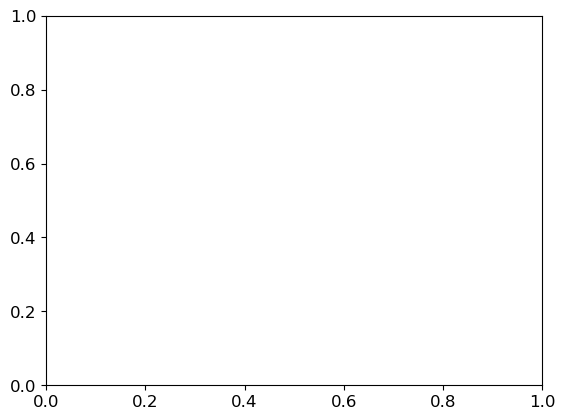

In [8]:
############ Plot the best point's scatter plot ########
fig, ax = plt.subplots()

plt.scatter(wdv, poic[min_index, :])
plt.xlabel('Ground Reference (cm)', fontsize=fs)
plt.ylabel('InSAR Predictions (cm)', fontsize=16)

plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)
 
    
x = range(-4, 1)
ax.plot(x, x, label='45-Degree Line', color = 'red')
corr_coeff = np.corrcoef(wdv, poic[int(min_index[0]), :])[0, 1]
#plt.title('Y/X ' + str(lati) + ' ' + str(loni))
#plt.title('lalo ' + str(lati) + ' ' + str(loni))
plt.show()
r2 = corr_coeff * corr_coeff
print(corr_coeff)
print(r2)
plt.savefig('scatter.png')

In [ ]:
############### Plot Connected Component ##################################

!save_gdal.py inputs/ifgramStack_sub4.h5 -d connectComponent-20170307_20170319 --of GTiff

In [ ]:
!smallbaselineApp.py try_3.cfg --dostep modify_network
!smallbaselineApp.py try_3.cfg --dostep reference_point
!rm maskConnComp.h5
!generate_mask.py  inputs/ifgramStack.h5 --nonzero -o maskConnComp.h5 --update
!view.py maskConnComp.h5 --nodisplay --sub-lat 39.421 39.444 --sub-lon -122.166 -122.155

In [ ]:
!smallbaselineApp.py try_3.cfg --dostep reference_point
!rm maskConnComp.h5
!generate_mask.py  inputs/ifgramStack.h5 --nonzero -o maskConnComp.h5 --update
!view.py maskConnComp.h5 --nodisplay --sub-lat 39.419 39.444 --sub-lon -122.192 -122.170

In [ ]:
###################### Output the geotiff of interferograms ################

!save_gdal.py '/Users/hippobaby/Documents/Work/California/Processing/SacT4Ler/inputs/ifgramStack.h5' -d unwrapPhase-20171126_20171208 --sub-lat 39.4250 39.4450 --sub-lon -122.192 -122.170 --of GTiff --nodisplay

In [ ]:
!save_gdal.py -h


In [ ]:
tsobj = timeseries('timeseries.h5')
tsobj_s = timeseries('timeseries_singletbs.h5')

data = tsobj.read(datasetName=['20171126','20171208','20171220', '20180101', '20180113', '20180125'])
data_full = tsobj.read(datasetName=['20171009','20171021','20171102','20171114', '20171126','20171208','20171220', '20180101', '20180113', '20180125', '20180206', '20180218', '20180302'])
data_s = tsobj_s.read(datasetName=['20171126','20171208','20171220', '20180101', '20180113', '20180125'])
#dates = ['20171009','20171021','20171102','20171114', '20171126','20171208','20171220', '20180101', '20180113', '20180125', '20180206', '20180218', '20180302']
dates_full = ['20171009','20171021','20171102','20171114', '20171126','20171208','20171220', '20180101', '20180113', '20180125', '20180206', '20180218', '20180302']

In [ ]:
dates

In [ ]:
#################### Plot for the GOOD period of time only #########################
yi = 10
xi = 29


inc_angle = readfile.read('inputs/geometryGeo.h5', datasetName='incidenceAngle')[0]
coherence = readfile.read('inputs/ifgramStack.h5', datasetName='coherence')[0]
angle = inc_angle[yi, xi]
angle = angle / 180 * np.pi 

rg = list(range(4, 10))
poi = data_full[rg, yi, xi]
poic = poi / np.cos(angle)
poic = poic * 100
poic = poic - poic[0]

path = './wd/wdts.csv'
wdf = pd.read_csv(path)
wd = wdf.iloc[:, 2]
wdt = wd[25 : 31] ## from 20171126 to 20180125
wdt = wdt - wdt.iloc[0]
ID = list(range(len(wdt)))

In [ ]:
type(dates)



In [ ]:
################# Plot for the GOOD period of time ###################

fig, ax = plt.subplots()
plt.scatter(ID, wdt, label = 'Ground Truth')
plt.scatter(ID, poic, label = 'InSAR estimates')
plt.xlabel('SAR acquisition dates')
plt.ylabel('Ground Truth vs. InSAR Predictions')
indices = rg  # Index array
xltick = [dates[i] for i in rg]
plt.xticks(ID, xltick)
plt.title('Y/X ' + str(yi) + ' ' + str(xi))

# Show the plot
plt.legend()
plt.show()
fig.savefig('./results/ YX ' + str(yi) + ' ' + str(xi) + '.png')  # Save as PNG file

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
plt.scatter(wdt, poic)
plt.xlabel('Ground Truth')
plt.ylabel('InSAR Predictions')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))
ax.axis('equal')
fig.savefig('./results/ scatter YX ' + str(yi) + ' ' + str(xi) + '.png')  # Save as PNG file

In [ ]:
########### Plot Coherence ######################

fig, ax = plt.subplots()
rg = list(range(150, 181, 6))
cohp = coherence[rg, yi, xi]
plt.scatter(ID, cohp)
plt.xlabel('ID')
plt.ylabel('InSAR Coherence')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))
ax.set_ylim(0, 1)

In [ ]:
pwd

In [ ]:
##################### Full time series #####################################

yi = 10
xi = 28
data_full = tsobj.read(datasetName=['20171009','20171021','20171102','20171114', '20171126','20171208','20171220', '20180101', '20180113', '20180125', '20180206', '20180218', '20180302'])

inc_angle = readfile.read('inputs/geometryGeo.h5', datasetName='incidenceAngle')[0]
angle = inc_angle[yi, xi]
angle = angle / 180 * np.pi 

poi = data_full[:, yi, xi]
poic = poi / np.cos(angle)
poic = poic * 100
poic

path = './wd/wdts.csv'
wdf = pd.read_csv(path)
wd = wdf.iloc[:, 2]
wdt = wd[21 : 34] ## from 20171126 to 20180125
wdt = wdt - wdt.iloc[0]
ID = list(range(len(poic)))

rg = range(0, len(poic), 3)
indices = rg  # Index array
xltick = [dates_full[i] for i in rg]
IDtick = [ID[i] for i in rg]

fig, ax = plt.subplots()
plt.scatter(ID, wdt)
plt.scatter(ID, poic)
plt.xlabel('SAR acquisition ID')
plt.ylabel('Ground Truth vs. InSAR Predictions')
plt.xticks(IDtick, xltick)
plt.title('Y/X ' + str(yi) + ' ' + str(xi))
plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1) 
print(xltick)
plt.savefig('fulltspng', dpi=300, bbox_inches='tight')

In [ ]:
fig, ax = plt.subplots()

plt.scatter(wdt, poic)
plt.xlabel('water depth')
plt.ylabel('InSAR Coherence')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))
ax.set_ylim(0, 1)

In [ ]:
yi = 15
xi = 27


inc_angle = readfile.read('inputs/geometryGeo.h5', datasetName='incidenceAngle')[0]
coherence = readfile.read('inputs/ifgramStack.h5', datasetName='coherence')[0]
angle = inc_angle[yi, xi]
angle = angle / 180 * np.pi 

rg = list(range(1, 5))
poi = data_full[rg, yi, xi]
poic = poi / np.cos(angle)
poic = poic * 100
poic = poic - poic[0]

path = './wd/wdts.csv'
wdf = pd.read_csv(path)
wd = wdf.iloc[:, 2]
wdt = wd[22 : 26] ## 
wdt = wdt - wdt.iloc[0]
ID = list(range(len(wdt)))

fig, ax = plt.subplots()
plt.scatter(ID, wdt)
plt.scatter(ID, poic)
plt.xlabel('SAR acquisition ID')
plt.ylabel('Ground Truth vs. InSAR Predictions')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))

# Show the plot
plt.show()
fig.savefig('./results/ YX ' + str(yi) + ' ' + str(xi) + '.png')  # Save as PNG file

In [ ]:
fig, ax = plt.subplots()
rg = list(range(132, 151, 6))
cohp = coherence[rg, yi, xi]
plt.scatter(ID, cohp)
plt.xlabel('ID')
plt.ylabel('InSAR Coherence')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))
ax.set_ylim(0, 1)

In [ ]:
yi = 15
xi = 27


inc_angle = readfile.read('inputs/geometryGeo.h5', datasetName='incidenceAngle')[0]
coherence = readfile.read('inputs/ifgramStack.h5', datasetName='coherence')[0]
angle = inc_angle[yi, xi]
angle = angle / 180 * np.pi 

rg = list(range(10, 13))
poi = data_full[rg, yi, xi]
poic = poi / np.cos(angle)
poic = poic * 100
poic = poic - poic[0]

path = './wd/wdts.csv'
wdf = pd.read_csv(path)
wd = wdf.iloc[:, 2]
wdt = wd[31 : 34] ## 
wdt = wdt - wdt.iloc[0]
ID = list(range(len(wdt)))

fig, ax = plt.subplots()
plt.scatter(ID, wdt)
plt.scatter(ID, poic)
plt.xlabel('SAR acquisition ID')
plt.ylabel('Ground Truth vs. InSAR Predictions')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))

# Show the plot
plt.show()
fig.savefig('./results/ YX ' + str(yi) + ' ' + str(xi) + '.png')  # Save as PNG file

In [ ]:
fig, ax = plt.subplots()
rg = list(range(186, 199, 6))
cohp = coherence[rg, yi, xi]
plt.scatter(ID, cohp)
plt.xlabel('ID')
plt.ylabel('InSAR Coherence')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))
ax.set_ylim(0, 1)

In [ ]:
yi = 7
xi = 28


inc_angle = readfile.read('inputs/geometryGeo.h5', datasetName='incidenceAngle')[0]
angle = inc_angle[yi, xi]
angle = angle / 180 * np.pi 

poi = data[:, yi, xi]
poic = poi / np.cos(angle)
poic = poic * 100
poic

path = './wd/wdts_2.csv'
wdf2 = pd.read_csv(path)
wd2 = wdf2.iloc[:, 2]
wdt2 = wd2[25 : 31] ## from 20171126 to 20180125
wdt2 = wdt2 - wdt2.iloc[0]

In [ ]:
fig, ax = plt.subplots()
plt.scatter(ID, wdt2)
plt.scatter(ID, poic)
plt.xlabel('SAR acquisition ID')
plt.ylabel('Ground Truth vs. InSAR Predictions')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))

# Show the plot
plt.show()
fig.savefig('./results/ YX ' + str(yi) + ' ' + str(xi) + '.png')  # Save as PNG file

In [ ]:
len(wdt)

In [ ]:
##################### Full time series #####################################

yi = 7
xi = 28
data_full = tsobj.read(datasetName=['20171009','20171021','20171102','20171114', '20171126','20171208','20171220', '20180101', '20180113', '20180125', '20180206', '20180218', '20180302'])

inc_angle = readfile.read('inputs/geometryGeo.h5', datasetName='incidenceAngle')[0]
angle = inc_angle[yi, xi]
angle = angle / 180 * np.pi 

poi = data_full[:, yi, xi]
poic = poi / np.cos(angle)
poic = poic * 100
poic

path = './wd/wdts.csv'
wdf = pd.read_csv(path)
wd = wdf.iloc[:, 2]
wdt = wd[21 : 34] ## from 20171126 to 20180125
wdt = wdt - wdt.iloc[0]
ID = list(range(len(wdt)))

rg = range(len(poic))
indices = rg  # Index array
xltick = [data_full[i] for i in rg]

ID = list(range(len(poic)))
fig, ax = plt.subplots()
plt.scatter(ID, wdt)
plt.scatter(ID, poic)
plt.xlabel('SAR acquisition ID')
plt.ylabel('Ground Truth vs. InSAR Predictions')
plt.xticks(ID, xltick)
plt.title('Y/X ' + str(yi) + ' ' + str(xi))



In [ ]:
wdt

In [ ]:
fig, ax = plt.subplots()

plt.scatter(wdt, poic)
plt.xlabel('water depth')
plt.ylabel('InSAR Coherence')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))
ax.set_ylim(0, 1)

In [ ]:
cohp

In [ ]:
rg = list(range(126, 199, 6))
cohp = coherence[rg, yi, xi]
cohp
fig, ax = plt.subplots()
plt.scatter(ID, cohp)
plt.xlabel('SAR acquisition ID')
plt.ylabel('Coherence')
plt.title('Y/X ' + str(yi) + ' ' + str(xi))